In [1]:
# Colab bootstrap. Only clones when the notebook is NOT already running inside
# a checkout -- running it unconditionally creates a nested ECS171-Project/ copy
# and writes every artifact (models/, figures/) in there instead of the repo.
import os, pathlib

if not pathlib.Path("cleaned_data").exists():
    os.system("git clone https://github.com/akaplin23/ECS171-Project.git")
    os.chdir("ECS171-Project")

print("working directory:", pathlib.Path.cwd())


working directory: /Users/kyisinthant/Documents/ECS171-Project


###**Decision Tree Baseline Model**

In [2]:
import pandas as pd
import numpy as np

# Load pre-split CSV files
train_df = pd.read_csv("cleaned_data/heart_train_processed.csv")
val_df   = pd.read_csv("cleaned_data/heart_val_processed.csv")
test_df  = pd.read_csv("cleaned_data/heart_test_processed.csv")

# Separate input features X from binary target variable (y: 0 = Normal, 1 = HeartDisease)
X_train = train_df.drop(columns=["HeartDisease"])
y_train = train_df["HeartDisease"]

X_val   = val_df.drop(columns=["HeartDisease"])
y_val   = val_df["HeartDisease"]

X_test  = test_df.drop(columns=["HeartDisease"])
y_test  = test_df["HeartDisease"]

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print("Nulls remaining:", X_train.isna().sum().sum() + X_val.isna().sum().sum() + X_test.isna().sum().sum())
print("Columns:", list(X_train.columns))

Train: (587, 16) | Val: (147, 16) | Test: (184, 16)
Nulls remaining: 0
Columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'Chol_missing', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


**Training an Unpruned Decision Tree**

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

# initialize decision tree and fit on training set
# random_state=0 builds the tree identically each time you run code
dt = DecisionTreeClassifier(random_state=0)
dt.fit(X_train, y_train)

# predictions and probabilities
train_preds = dt.predict(X_train)
val_preds = dt.predict(X_val)
val_probs = dt.predict_proba(X_val)[:, 1]

# base Metrics
print("Vanilla Decision Tree (Unpruned):")
print(f"Tree Depth     : {dt.get_depth()} | Leaves: {dt.get_n_leaves()}")
print(f"Train Accuracy : {accuracy_score(y_train, train_preds):.4f}")
print(f"Val Accuracy   : {accuracy_score(y_val, val_preds):.4f}")
print(f"Val Recall     : {recall_score(y_val, val_preds):.4f}")
print(f"Val F1-Score   : {f1_score(y_val, val_preds):.4f}")
print(f"Val ROC-AUC    : {roc_auc_score(y_val, val_probs):.4f}")


Vanilla Decision Tree (Unpruned):
Tree Depth     : 13 | Leaves: 95
Train Accuracy : 1.0000
Val Accuracy   : 0.8027
Val Recall     : 0.8025
Val F1-Score   : 0.8176
Val ROC-AUC    : 0.8027


**Initial Metric Evaluation**


---

The training accuracy is 1.0 while the validation accyracy is 0.80. This suggests the tree overfits to the noise in the training set and doesn't generalize as well to unseen data. This is because there is no max_depth so the tree keeps splitting until it has pure leaf nodes, hence why the training accuracy is 1.0. The tree ends up with a depth of 13 and 95 leaves. Accuracy looks at one cutoff (0.50) while ROC-AUC looks at all possible cutoffs but Validation Accuracy and Validation ROC-AUC are the same.

Tuning Tree Pruning Hyperparameters on Validation Set

In [4]:
tuning_results = []

# search across split criteria, max tree depths, and min leaf sizes
for criterion in ["gini", "entropy"]:
    for max_depth in [2, 3, 4, 5, 6, 8, 10]:
        for min_samples_leaf in [1, 5, 10, 20]:
            model = DecisionTreeClassifier(
                criterion=criterion,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                random_state=0
            )
            # fit on X_train and evaluate on X_val
            model.fit(X_train, y_train)
            val_probs = model.predict_proba(X_val)[:, 1]
            val_preds = model.predict(X_val)

            tuning_results.append({
                "criterion": criterion,
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf,
                "val_auc": roc_auc_score(y_val, val_probs),
                "val_acc": accuracy_score(y_val, val_preds),
                "val_recall": recall_score(y_val, val_preds),
                "val_f1": f1_score(y_val, val_preds),
                "model": model
            })

# sort by highest Validation ROC-AUC
tuning_df = pd.DataFrame(tuning_results).sort_values(by="val_auc", ascending=False)

print("Top Pruned Decision Tree Configurations on Validation Set: ")
print(tuning_df.drop(columns=["model"]).head(10).to_string(index=False))

# winning pruned tree
best_dt = tuning_df.iloc[0]["model"]

Top Pruned Decision Tree Configurations on Validation Set: 
criterion  max_depth  min_samples_leaf  val_auc  val_acc  val_recall   val_f1
  entropy          5                20 0.896745 0.809524    0.827160 0.827160
  entropy          4                20 0.893939 0.809524    0.827160 0.827160
  entropy          6                20 0.891601 0.809524    0.827160 0.827160
  entropy         10                20 0.890853 0.809524    0.827160 0.827160
  entropy          8                20 0.890853 0.809524    0.827160 0.827160
     gini          4                20 0.882061 0.809524    0.827160 0.827160
  entropy          8                10 0.881126 0.789116    0.851852 0.816568
     gini          6                20 0.881033 0.809524    0.827160 0.827160
     gini          5                20 0.879349 0.809524    0.827160 0.827160
  entropy         10                10 0.878881 0.789116    0.851852 0.816568


**Evaluating 'Winning' Configuration**


---

For the unpruned decision tree ROC-AUC was 0.8027 but the winning configuration has a validation ROC-AUC of 0.896745.

All but one of the top ten configurations has min_samples_leaf = 20. This suggests that 20 is the sweet spot when it comes to min_samples_leaf. Too small amount of samples per leaf can cause the model to memorize random noise and too large would miss relationships between the dataset and would lower accuracy and ROC-AUC.

Entropy beats gini in all of the top 5 models. Entropy measures class uncertainty inside each node and chooses splits that maximize information gain. Typically, Gini and Entropy perform very similarly but Entropy seems to produce slightly better probability separations in this dataset.

**Final Evaluation on X_test**

In [5]:
from sklearn.metrics import classification_report, confusion_matrix

# final probabilities and predictions for X_test.
# Threshold explicitly at 0.5 rather than using .predict(): sklearn's argmax
# sends exact 0.5/0.5 leaf ties to class 0, which with min_samples_leaf=20
# produces many ties and silently scores the tree above 0.5. Every model in
# this project is compared at the same 0.5 cutoff.
test_probs = best_dt.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)

# computing true negative rate and recall
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()
specificity = tn / (tn + fp) # True negative rate
sensitivity = tp / (tp + fn) # Recall

# full evaluation report
print("FINAL DECISION TREE TEST SET RESULTS:")
print(classification_report(y_test, test_preds, digits=4))
print(f"Accuracy    : {accuracy_score(y_test, test_preds):.4f}")
print(f"Sensitivity : {sensitivity:.4f} (Recall for HeartDisease=1)")
print(f"Specificity : {specificity:.4f} (Recall for HeartDisease=0)")
print(f"F1-Score    : {f1_score(y_test, test_preds):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, test_probs):.4f}")
print(f"\nConfusion Matrix:\n[[TN={tn}, FP={fp}]\n [FN={fn}, TP={tp}]]")

FINAL DECISION TREE TEST SET RESULTS:


              precision    recall  f1-score   support

           0     0.8611    0.7561    0.8052        82
           1     0.8214    0.9020    0.8598       102

    accuracy                         0.8370       184
   macro avg     0.8413    0.8290    0.8325       184
weighted avg     0.8391    0.8370    0.8355       184

Accuracy    : 0.8370
Sensitivity : 0.9020 (Recall for HeartDisease=1)
Specificity : 0.7561 (Recall for HeartDisease=0)
F1-Score    : 0.8598
ROC-AUC     : 0.9154

Confusion Matrix:
[[TN=62, FP=20]
 [FN=10, TP=92]]


**Final Decision Tree Result Evaluation**


---

The ROC-AUC jumped from 0.8027 from the unpruned tree to 0.9154. This suggests that the model generalizes well to unseen patients. The sensitivity and specificity are balanced. However, in a dataset like this Recall for HeartDisease is more important because we don't want to send HeartDisease patients home. There was 16/102 patients given a false negative.

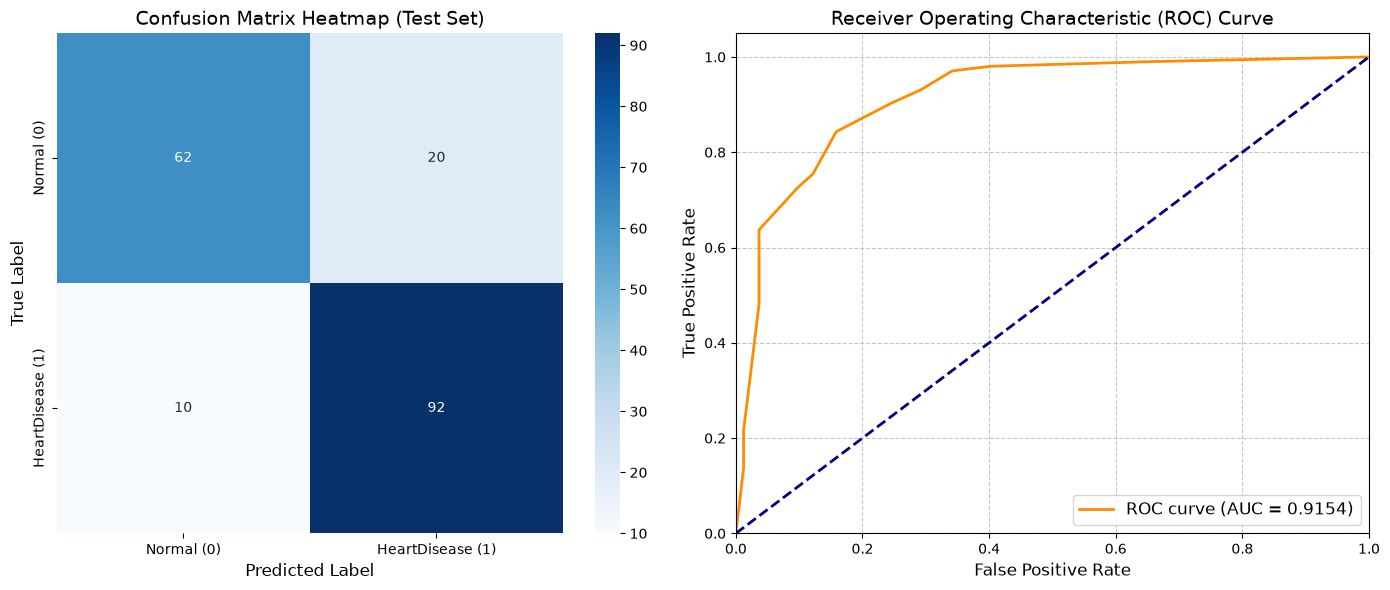

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, test_probs)
roc_auc = auc(fpr, tpr)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# confusion matrix heatmap
sns.heatmap(
    confusion_matrix(y_test, test_preds),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal (0)", "HeartDisease (1)"],
    yticklabels=["Normal (0)", "HeartDisease (1)"],
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix Heatmap (Test Set)", fontsize=14)
axes[0].set_xlabel("Predicted Label", fontsize=12)
axes[0].set_ylabel("True Label", fontsize=12)

# ROC curve plot
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("False Positive Rate", fontsize=12)
axes[1].set_ylabel("True Positive Rate", fontsize=12)
axes[1].set_title("Receiver Operating Characteristic (ROC) Curve", fontsize=14)
axes[1].legend(loc="lower right", fontsize=12)
axes[1].grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

Visualizing Tree

Decision Tree Feature Importances:
          Feature  Importance
      ST_Slope_Up    0.562926
     Chol_missing    0.126336
   ExerciseAngina    0.101279
              Sex    0.087692
            MaxHR    0.067525
          Oldpeak    0.027670
              Age    0.026573
        RestingBP    0.000000
      Cholesterol    0.000000
        FastingBS    0.000000
ChestPainType_ATA    0.000000
ChestPainType_NAP    0.000000
 ChestPainType_TA    0.000000
RestingECG_Normal    0.000000
    RestingECG_ST    0.000000
    ST_Slope_Flat    0.000000


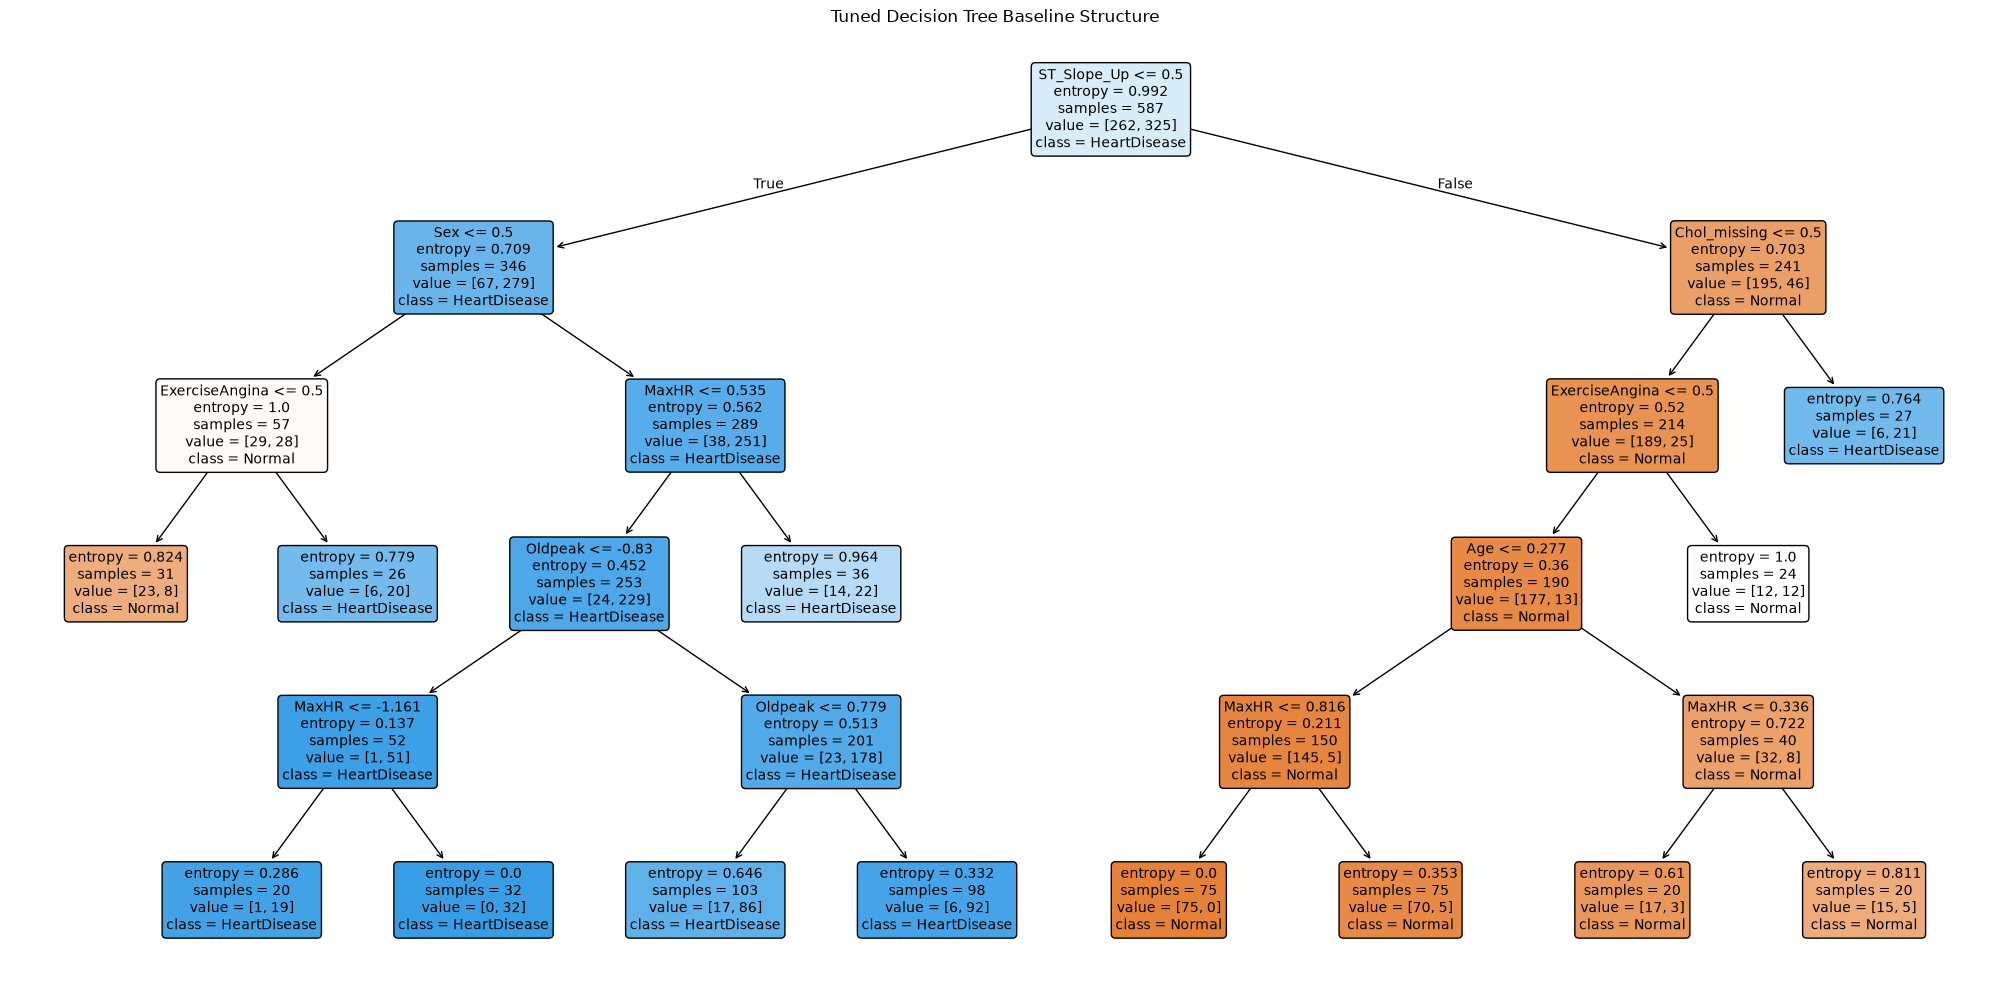

In [7]:
import pathlib
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# rank features by total impurity reduction
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_dt.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Decision Tree Feature Importances:")
print(importance_df.to_string(index=False))

# plot pruned decision tree structure
plt.figure(figsize=(20, 10))
plot_tree(
    best_dt,
    feature_names=list(X_train.columns),
    class_names=["Normal", "HeartDisease"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Tuned Decision Tree Baseline Structure")
plt.tight_layout()
pathlib.Path("models").mkdir(exist_ok=True)
plt.savefig("models/decision_tree_structure.png", dpi=300)
plt.show()

**Why do some features have 0.0 importance?**

Since the pruned tree has parameters max_depth and min_sample_leaf, the tree can only do a fixed number of splits so not all features are chosen for a split get an importance of 0.0.

In [8]:
import joblib
import pathlib

# ensure models/ folder exists
pathlib.Path("models").mkdir(exist_ok=True)

# save trained Decision Tree model snapshot
joblib.dump(best_dt, "models/decision_tree_baseline.joblib")

# save test set ground truth, binary predictions, and probabilities
pd.DataFrame({
    "y_true": y_test,
    "dt_pred": test_preds,
    "dt_prob": test_probs
}).to_csv("models/dt_test_predictions.csv", index=False)

print("Saved Decision Tree model and test predictions successfully!")

Saved Decision Tree model and test predictions successfully!
